In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

from scipy.spatial.distance import cdist

After importing libraries, i import a simple dataset to work with

In [2]:
df_tmp= pd.DataFrame(pd.read_csv("./House_Rent_Dataset.csv"))
df= df_tmp[["BHK", "Bathroom", "Size", "Rent"]]
#df["Rent"] = df["Rent"]/10000
df.head()

,BHK,Bathroom,Size,Rent
0,2,2,1100,10000
1,2,1,800,20000
2,2,1,1000,17000
3,2,1,800,10000
4,2,1,850,7500


train test split and making the data ready for use

In [6]:
print(df.info())

X = np.array(df.drop(["Rent"], axis=1))[:2000]
y = np.array(df["Rent"])[:2000]


X_train, X_unseen, y_train, y_unseen = train_test_split(
    X, y, test_size=0.3, random_state=42
)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_unseen, y_unseen, test_size=0.5, random_state=42
)


print(X_train.shape)
print(y_train.shape)

print(X_valid.shape)
print(y_valid.shape)

print(X_test.shape)
print(y_test.shape)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   BHK       4746 non-null   int64
 1   Bathroom  4746 non-null   int64
 2   Size      4746 non-null   int64
 3   Rent      4746 non-null   int64
dtypes: int64(4)
memory usage: 148.4 KB
None
(1400, 3)
(1400,)
(300, 3)
(300,)
(300, 3)
(300,)


# implementing models from scratch

In [8]:
def mse_sample(y_pred, y_true):
    n = y_pred.shape[0]
    return np.sum(np.square(y_pred - y_true)) / n


def simple_knn(k_low, k_up, arrx_train, arrx_test,
               arry_train, arry_test, want_plot=True):

    euclid = cdist(arrx_test, arrx_train, metric='euclidean')

    mses = []
    k_values = list(range(k_low, k_up + 1))
    y_preds = []

    for k in k_values:

        K_indices = np.argsort(euclid, axis=1)[:, :k]

        y_pred = arry_train[K_indices].mean(axis=1)
        y_preds.append(y_pred)

        mse = mse_sample(y_pred, arry_test)
        mses.append(float(mse))

    optimal_index = np.argmin(mses)
    optimal_k = k_values[optimal_index]

    if want_plot:

        plt.figure(figsize=(15, 8))

        plt.plot(
            k_values, mses,
            marker='o',
            linestyle='-',
            color='b',
            linewidth=2
        )

        plt.title('Validation MSE vs. Number of Neighbors (k)', fontsize=14)
        plt.xlabel('k (Number of Neighbors)', fontsize=12)
        plt.ylabel('Mean Squared Error (MSE)', fontsize=12)

        plt.grid(True, linestyle='-', alpha=0.6)
        plt.xticks(k_values)

        plt.show()

        print(f"Opt k is {optimal_k}")

    return optimal_k, y_preds[optimal_index], mses[optimal_index]


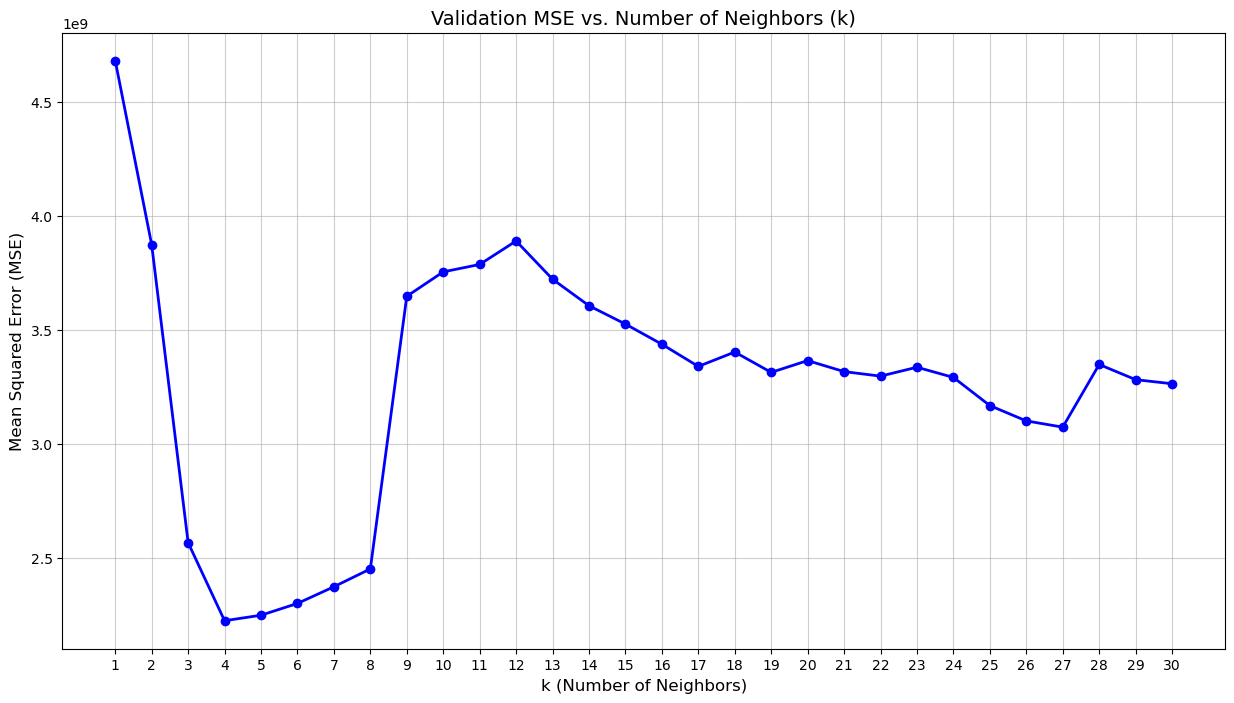

Opt k is 4
Optimal K: 4
Validation MSE: 2223944423.6739583
Test MSE: 2223944423.6739583


In [9]:

euclid = cdist(X_valid, X_train, metric='euclidean')


opt_val_k, y_valid_pred, optimal_valid_mse = simple_knn(
    1, 30,
    X_train, X_valid,
    y_train, y_valid
)


print("Optimal K:", opt_val_k)
print("Validation MSE:", optimal_valid_mse)
print("Test MSE:", optimal_valid_mse)

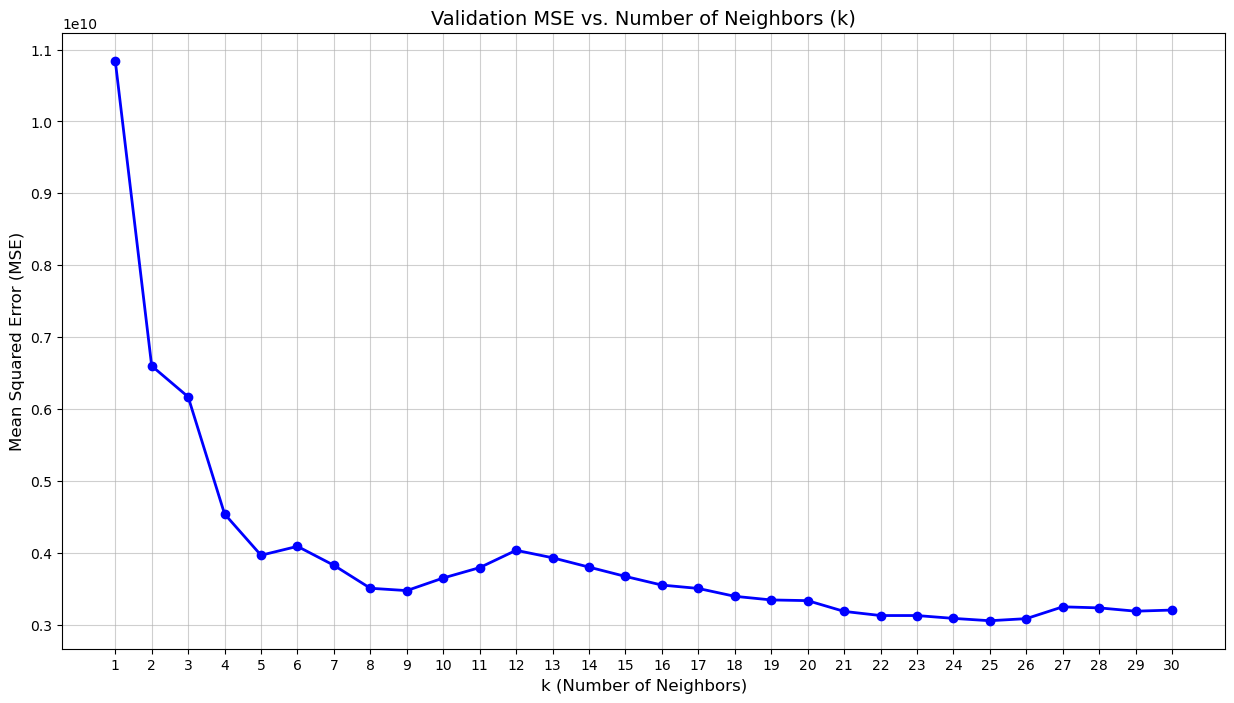

Opt k is 25
Optimal K: 25
Validation MSE: 3053035834.1237707
Test MSE: 3053035834.1237707


In [10]:
opt_test_k, y_test_pred, optimal_test_mse = simple_knn(
    1, 30,
    X_train, X_test,
    y_train, y_test,
    want_plot = True
)


print("Optimal K:", opt_test_k)
print("Validation MSE:", optimal_test_mse)
print("Test MSE:", optimal_test_mse)

In [12]:
!jupyter nbconvert --to pdf "KNN_from_scratch.ipynb"


[NbConvertApp] Converting notebook KNN_from_scratch.ipynb to pdf
[NbConvertApp] Support files will be in KNN_from_scratch_files\
[NbConvertApp] Making directory .\KNN_from_scratch_files
[NbConvertApp] Writing 33485 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | b had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 126262 bytes to KNN_from_scratch.pdf
